# Información del dataset

**Problema:** predecir el precio de venta de una propiedad en Pakistán a partir de sus características (regresión supervisada; target: `price`).

**Fuente:** anuncios de [zameen.com](https://www.zameen.com) en cinco ciudades (Karachi, Lahore, Islamabad, Rawalpindi y Faisalabad), del conjunto [Zameen.com Property Data Pakistan](https://www.kaggle.com/datasets/huzzefakhan/zameencom-property-data-pakistan) de Kaggle. Archivo `Property.csv`, que se guarda en `data/bronze/` y no se sube al repositorio.

> Empezamos con `Entities.csv`, una versión del mismo conjunto. Al revisarla vimos que la superficie estaba mal procesada: al pasar el texto original (`"5.6 Marla"`) a pies cuadrados se perdió el punto decimal (se leyó como 56 marla), de modo que **en torno al 35 % de las superficies estaban multiplicadas por 10**. Además le faltaban unos 23.000 anuncios. Por eso partimos de `Property.csv`.

Este notebook describe los datos **tal y como llegan**, sin modificarlos. Las correcciones se hacen en `data_cleaning_pre_train_test_split.ipynb`.

## 1. Carga de datos

El archivo usa `;` como separador y no tiene columna de índice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/bronze/Property.csv", sep=";")
df.shape

(191393, 17)

## 2. Primer vistazo

Los primeros registros. `page_url` es larga y única por anuncio, y `area` es **texto** con la unidad local (`Marla` o `Kanal`).

In [3]:
df.head(5)

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


## 3. Dimensiones, tipos y valores nulos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 191393 entries, 0 to 191392
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    191393 non-null  int64  
 1   location_id    191393 non-null  int64  
 2   page_url       191393 non-null  str    
 3   property_type  191393 non-null  str    
 4   price          191393 non-null  int64  
 5   location       191393 non-null  str    
 6   city           191393 non-null  str    
 7   province_name  191393 non-null  str    
 8   latitude       191393 non-null  float64
 9   longitude      191393 non-null  float64
 10  baths          191393 non-null  int64  
 11  area           191393 non-null  str    
 12  purpose        191393 non-null  str    
 13  bedrooms       191393 non-null  int64  
 14  date_added     191393 non-null  str    
 15  agency         144014 non-null  str    
 16  agent          144013 non-null  str    
dtypes: float64(2), int64(5), str(10)
memory 

El dataset tiene **191.393 anuncios y 17 columnas**. Los únicos nulos están en `agency` y `agent` (24,8 % cada una).

Hay dos tipos que no son los que parecen:
- `area` es texto, no un número.
- `date_added` es texto con formato `MM-DD-YYYY`, no una fecha.

## 4. Estadísticos descriptivos

In [5]:
num = ["price", "latitude", "longitude", "baths", "bedrooms"]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
price,191393.0,1.644655e+07,3.416412e+07,0.000000,80000.000000,7.300000e+06,1.800000e+07,2.000000e+09
latitude,191393.0,3.010459e+01,3.645941e+00,11.052446,24.972287,3.146356e+01,3.355087e+01,7.318409e+01
longitude,191393.0,7.157299e+01,3.080463e+00,25.906027,67.152597,7.307774e+01,7.422822e+01,8.016143e+01
baths,191393.0,2.865956e+00,2.435332e+00,0.000000,0.000000,3.000000e+00,4.000000e+00,4.030000e+02
bedrooms,191393.0,3.171516e+00,1.952403e+00,0.000000,2.000000,3.000000e+00,4.000000e+00,6.800000e+01


El `describe()` ya avisa de varios problemas:

- `price` tiene un mínimo de 0 y un máximo de 2.000 millones de rupias, y la media (16,4 M) está muy por encima de la mediana (7,3 M): cola larga a la derecha.
- `baths` llega a 403 y `bedrooms` a 68.
- `latitude` llega a 73 y `longitude` baja a 25,9, valores que no corresponden a Pakistán.
- El cuartil del 25 % de `baths` es 0: hay muchísimos ceros.

## 5. Diccionario de variables

El `dtype` de pandas no es el tipo real de la variable, por eso se indica el tipo real y el uso previsto.

| Variable | Descripción | Tipo real | dtype | Uso previsto |
|---|---|---|---|---|
| `property_id` | Identificador del anuncio | Identificador | int64 | Descartar |
| `location_id` | Subzona dentro de la zona: fase, sector o bloque | Cualitativa nominal de alta cardinalidad (4.321 valores) | int64 | Predictor mediante el precio medio de la subzona (después del split) |
| `page_url` | Enlace al anuncio | Texto único | object | Descartar |
| `property_type` | Tipo de inmueble (House, Flat, Upper/Lower Portion, Room, Penthouse, Farm House) | Cualitativa nominal | object | Predictor (codificar) |
| `price` | Precio publicado, en rupias (PKR) | Cuantitativa continua | int64 | **Target** (se pasa a euros) |
| `location` | Zona general, por ejemplo «DHA Defence» | Cualitativa nominal de alta cardinalidad (1.536 valores) | object | Predictor mediante el precio medio de la zona (después del split) |
| `city` | Ciudad | Cualitativa nominal | object | Predictor (codificar) |
| `province_name` | Provincia | Cualitativa nominal (la determina `city`) | object | Redundante con `city` |
| `latitude`, `longitude` | Coordenadas de la **subzona**, no de la vivienda | Cuantitativa continua | float64 | Resumir en `dist_centro_km` |
| `baths` | Número de baños (el 0 suele ser «no rellenado») | Cuantitativa discreta | int64 | Predictor |
| `bedrooms` | Número de habitaciones (el 0 suele ser «no rellenado») | Cuantitativa discreta | int64 | Predictor |
| `area` | Superficie con su unidad local (`Marla` o `Kanal`) | Texto → cuantitativa continua | object | Convertir a m² y usar como predictor |
| `purpose` | Venta o alquiler | Cualitativa nominal (binaria) | object | Filtrar (`For Sale`) y descartar |
| `date_added` | Fecha de la última actualización del anuncio | Fecha | object | Convertir a `datetime`; uso por decidir |
| `agency`, `agent` | Agencia y agente | Cualitativa nominal de alta cardinalidad | object | Descartar (25 % de nulos) |

## 6. Calidad de los datos

### 6.1 Valores nulos

In [6]:
nulos = df.isna().sum().to_frame("nulos")
nulos["% sobre el total"] = (nulos["nulos"] / len(df) * 100).round(1)
nulos[nulos["nulos"] > 0]

,nulos,% sobre el total
agency,47379,24.8
agent,47380,24.8


Solo `agency` y `agent`, y las vamos a descartar, así que **no hace falta imputar nada**.

### 6.2 Duplicados y repeticiones

In [7]:
ids = ["property_id", "page_url", "agency", "agent"]
sin_ids = df.drop(columns=ids)

print("property_id repetidos:", df["property_id"].duplicated().sum())
print("page_url repetidas:   ", df["page_url"].duplicated().sum())

dup = sin_ids.duplicated().sum()
print(f"\nAnuncios idénticos en todo salvo los identificadores: {dup} ({dup / len(df):.1%})")

sin_fecha = [c for c in sin_ids.columns if c != "date_added"]
rep = sin_ids.duplicated(subset=sin_fecha).sum()
print(f"Anuncios idénticos en todo salvo la fecha:            {rep} ({rep / len(df):.1%})")

property_id repetidos: 0
page_url repetidas:    0



Anuncios idénticos en todo salvo los identificadores: 22758 (11.9%)
Anuncios idénticos en todo salvo la fecha:            62265 (32.5%)


El identificador y la URL no se repiten nunca, pero hay muchos anuncios que **solo se diferencian en la fecha**: un 32,5 % repite a otro en tipo, precio, zona, subzona, coordenadas, superficie, baños y habitaciones. Unas veces es el mismo inmueble publicado varias veces por el mismo agente; otras, casas distintas con valores «estándar» (parcelas de 5 o 10 marla, 1 kanal, precios redondos).

**Consecuencias:**
- Si no se quitan, el modelo vería el mismo dato en train y en test y la evaluación saldría inflada (fuga de información).
- Los duplicados deben quitarse **al final** de la limpieza, cuando ya se han borrado las columnas que distinguen las copias.
- Aun así, habrá anuncios muy parecidos que no son idénticos: la partición train/test debe agrupar los que puedan ser la misma vivienda.

### 6.3 La superficie (`area`)

La superficie viene como texto con unidad local. Para poder analizarla la convertimos a m² en una serie aparte (**sin modificar `df`**): 1 marla = 272,25 pies² y 1 kanal = 20 marla.

In [8]:
partes = df["area"].str.extract(r"^([\d.,]+)\s*(\w+)$")
print("Valores de area sin interpretar:", partes[0].isna().sum())
print(partes[1].value_counts().to_string())

numero = pd.to_numeric(partes[0].str.replace(",", "", regex=False))
print(f"\nSuperficies con decimales (p. ej. '5.6 Marla'): {(numero % 1 != 0).mean():.1%}")

PIES2_POR_UNIDAD = {"Marla": 272.25, "Kanal": 20 * 272.25}
M2_POR_PIE2 = 0.09290304
m2 = numero * partes[1].map(PIES2_POR_UNIDAD) * M2_POR_PIE2

venta = df["purpose"] == "For Sale"
resumen = m2[venta].groupby(df["property_type"]).describe(percentiles=[0.5, 0.99])
resumen[["count", "min", "50%", "99%", "max"]].round(0)

Valores de area sin interpretar: 0
1
Marla    153980
Kanal     37413

Superficies con decimales (p. ej. '5.6 Marla'): 32.4%


,count,min,50%,99%,max
property_type,,,,,
Farm House,628.0,56.0,2985.0,50586.0,210437.0
Flat,28610.0,0.0,121.0,415.0,871187.0
House,93809.0,0.0,202.0,1113.0,3147544.0
Lower Portion,1010.0,18.0,134.0,506.0,303514.0
Penthouse,295.0,46.0,212.0,869.0,1012.0
Room,25.0,15.0,101.0,544.0,556.0
Upper Portion,2641.0,10.0,126.0,506.0,6070.0


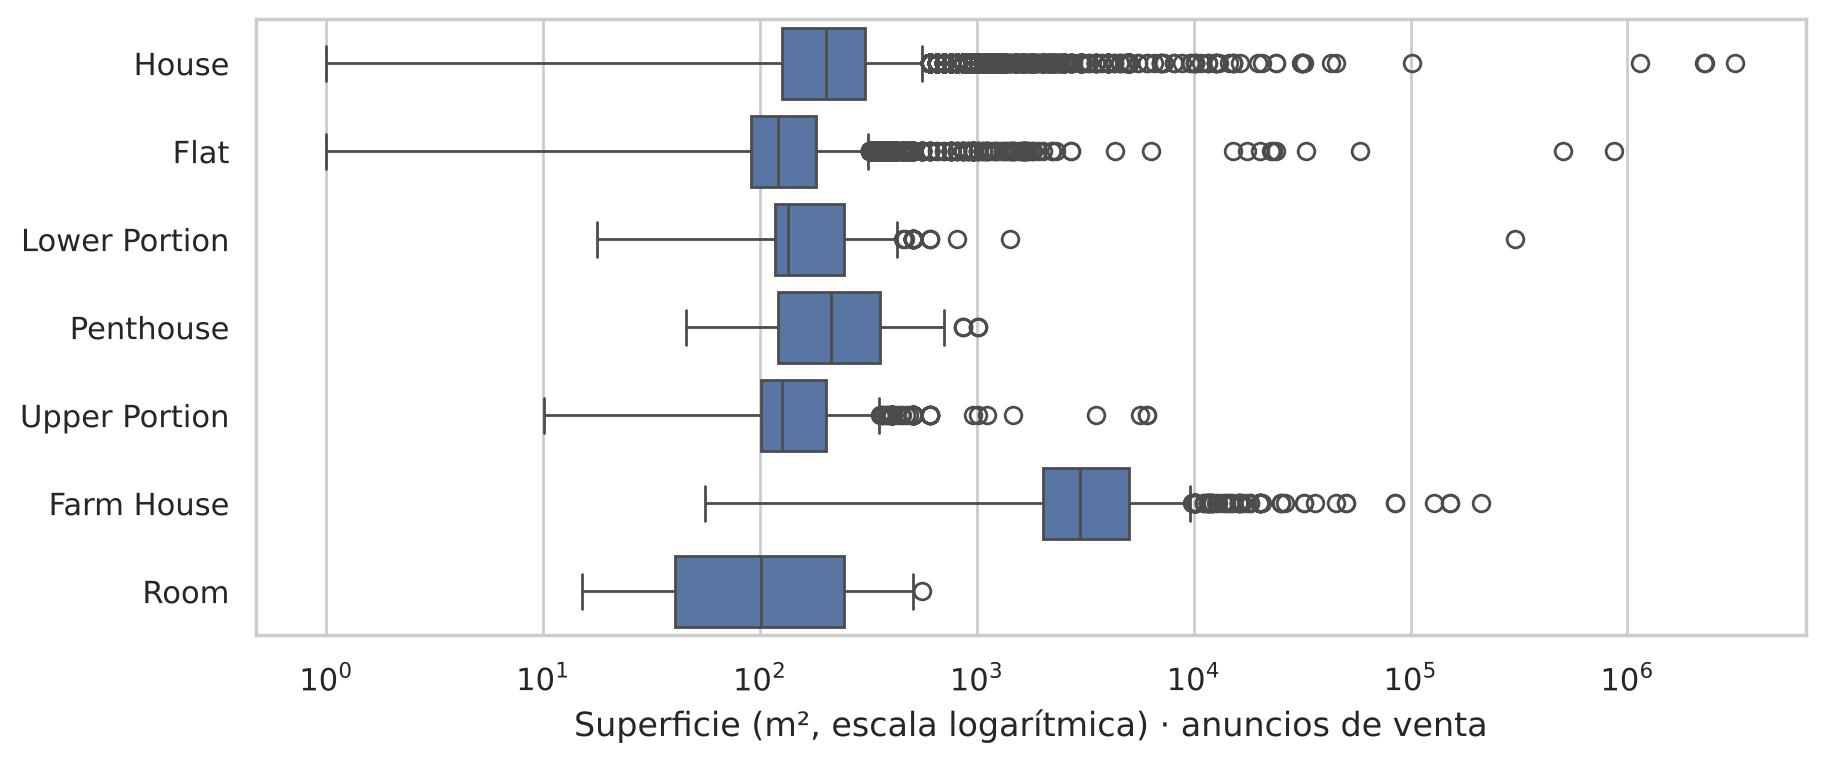

Superficie < 10 m² (ventas): 17
Superficie > 2.500 m² (ventas): 603
Pisos de venta de más de 250 m²: 3774 de 28610 (13%)


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=m2[venta].clip(lower=1), y=df.loc[venta, "property_type"], ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Superficie (m², escala logarítmica) · anuncios de venta")
ax.set_ylabel("")
plt.show()

v = venta
print("Superficie < 10 m² (ventas):", (m2[v] < 10).sum())
print("Superficie > 2.500 m² (ventas):", (m2[v] > 2500).sum())
pisos = v & (df["property_type"] == "Flat")
print(f"Pisos de venta de más de 250 m²: {(m2[pisos] > 250).sum()} de {pisos.sum()} ({(m2[pisos] > 250).mean():.0%})")

Con la conversión correcta, las medianas por tipo son razonables (piso ≈ 121 m², casa ≈ 202 m², granja ≈ 2.985 m²). Aun así quedan **valores extremos reales del scraping**: superficies de 0 m², de menos de 10 m² y de hasta 3,1 millones de m². Un 13 % de los pisos supera los 250 m², lo que no es habitual en un piso y habrá que revisar.

**Acción:** convertir `area` a m² (parseando también los números con coma de miles, como `"4,450"`) y fijar límites por tipo de propiedad en la limpieza previa. `Farm House` es el tipo con superficies grandes legítimas.

### 6.4 Ceros que son datos ausentes

In [10]:
cols = ["price", "baths", "bedrooms"]
ceros = pd.DataFrame({
    "ceros (todos)": [(df[c] == 0).sum() for c in cols],
    "% (todos)": [round((df[c] == 0).mean() * 100, 1) for c in cols],
    "% (solo ventas)": [round((df.loc[venta, c] == 0).mean() * 100, 1) for c in cols],
}, index=cols)
display(ceros)

por_ciudad = pd.DataFrame({
    "% con 0 baños": df[venta].groupby("city")["baths"].apply(lambda s: (s == 0).mean() * 100),
    "% con 0 habitaciones": df[venta].groupby("city")["bedrooms"].apply(lambda s: (s == 0).mean() * 100),
}).round(1).sort_values("% con 0 baños", ascending=False)
por_ciudad

,ceros (todos),% (todos),% (solo ventas)
price,3,0.0,0.0
baths,48130,25.1,23.6
bedrooms,24959,13.0,11.2


,% con 0 baños,% con 0 habitaciones
city,,
Faisalabad,64.6,53.9
Rawalpindi,31.6,18.5
Islamabad,24.2,14.6
Karachi,21.8,9.8
Lahore,18.2,4.5


Un 23,6 % de los anuncios de venta tiene 0 baños y un 11,2 %, 0 habitaciones. **No es aleatorio:** en Faisalabad el 64,6 % de los anuncios tiene 0 baños y el 53,9 %, 0 habitaciones, frente al 18,2 % y el 4,5 % de Lahore. Una casa de 4 habitaciones y 0 baños no existe: el anunciante no rellenó el campo.

**Consecuencia:** si se borran esas filas, el conjunto deja de representar a las ciudades (Faisalabad perdería la mayor parte de sus anuncios).

**Acción propuesta:** tratar el 0 como dato ausente (`NaN`) y rellenarlo **después** de la partición, con lo aprendido solo del train, añadiendo una columna que indique que faltaba. Esta decisión está pendiente de cerrar en el grupo.

El precio tiene solo 3 ceros, que se descartan junto con los precios absurdamente bajos.

### 6.5 Valores imposibles o fuera de rango

In [11]:
casas_venta = venta & (df["property_type"] == "House")
grandes = casas_venta & df["baths"].between(7, 12)

imposibles = pd.Series({
    "baths >= 7": (df["baths"] >= 7).sum(),
    "baths > 12": (df["baths"] > 12).sum(),
    "bedrooms > 12": (df["bedrooms"] > 12).sum(),
    "baths máximo": df["baths"].max(),
    "bedrooms máximo": df["bedrooms"].max(),
})
display(imposibles.to_frame("anuncios / valor"))

print(f"Casas en venta con 7 a 12 baños: {grandes.sum()} ({grandes.sum() / casas_venta.sum():.1%} de las casas)")
print(f"   superficie mediana: {m2[grandes].median():.0f} m²")
print(f"   precio mediano: {df.loc[grandes, 'price'].median() / 179.61:,.0f} € (1 € = 179,61 PKR)")

fuera = ~df["latitude"].between(23.5, 37.1) | ~df["longitude"].between(60.8, 77.9)
print(f"\nAnuncios con coordenadas fuera de Pakistán: {fuera.sum()}")
df[fuera][["city", "location", "latitude", "longitude"]].head()

,anuncios / valor
baths >= 7,9965
baths > 12,8
bedrooms > 12,40
baths máximo,403
bedrooms máximo,68


Casas en venta con 7 a 12 baños: 7563 (8.1% de las casas)
   superficie mediana: 506 m²
   precio mediano: 222,705 € (1 € = 179,61 PKR)

Anuncios con coordenadas fuera de Pakistán: 10


,city,location,latitude,longitude
2432,Karachi,North Karachi,72.610337,57.839654
4063,Islamabad,G-11,68.273802,51.871316
4962,Rawalpindi,Adiala Road,63.350414,39.176150
6369,Islamabad,F-6,47.656480,80.161430
6501,Rawalpindi,Range Road,68.435573,57.070567


- **Las casas con 7 a 12 baños son reales:** son 7.563 casas (el 8,1 %), con una superficie mediana de 506 m² (exactamente 1 kanal, una parcela grande estándar) y un precio mediano de unos 222.700 €. Los valores imposibles empiezan por encima de 12 baños (solo 8 anuncios) o 12 habitaciones (40 anuncios), con máximos de 403 y 68. Borrar todo lo que pase de 6 elimina casas caras de verdad.
- **Coordenadas:** hay 10 anuncios con coordenadas fuera de Pakistán. Algunas más caen dentro del país pero lejos de su ciudad, por eso la limpieza mide la distancia al centro de la ciudad y descarta lo que queda a más de 100 km.

**Acción:** descartar solo los valores imposibles (más de 12 baños o habitaciones) y filtrar las coordenadas por distancia al centro.

### 6.6 Variables categóricas

In [12]:
for c in ["purpose", "property_type", "city"]:
    tabla = df[c].value_counts().to_frame("anuncios")
    tabla["%"] = (tabla["anuncios"] / len(df) * 100).round(1)
    display(tabla)

pd.crosstab(df["city"], df["province_name"])

,anuncios,%
purpose,,
For Sale,127018,66.4
For Rent,64375,33.6


,anuncios,%
property_type,,
House,118915,62.1
Flat,40157,21.0
Upper Portion,18475,9.7
Lower Portion,11693,6.1
Room,1029,0.5
Farm House,725,0.4
Penthouse,399,0.2


,anuncios,%
city,,
Karachi,60484,31.6
Lahore,58736,30.7
Islamabad,40195,21.0
Rawalpindi,22898,12.0
Faisalabad,9080,4.7


province_name,Islamabad Capital,Punjab,Sindh
city,,,
Faisalabad,0,9080,0
Islamabad,40195,0,0
Karachi,0,0,60484
Lahore,0,58736,0
Rawalpindi,0,22898,0


- `purpose` mezcla ventas (66,4 %) y alquileres (33,6 %), con precios de escalas muy distintas (mediana de 13,5 M de rupias en venta frente a 45.000 en alquiler): **hay que quedarse solo con las ventas**, y mejor hacerlo lo primero.
- `property_type` está dominada por `House` (62 %); `Room`, `Farm House` y `Penthouse` son muy raras (alrededor del 0,5 % o menos cada una).
- `province_name` está determinada por `city` (cada ciudad pertenece a una sola provincia), así que no aporta información propia.
- `city` está desequilibrada: Karachi y Lahore suman el 62 %, Faisalabad el 4,7 %. La partición debe estratificarse por ciudad.

### 6.7 Ubicación y fechas

La ubicación tiene **tres niveles**.

In [13]:
print("Zonas distintas (location):         ", df["location"].nunique())
print("Pares (city, location):              ", df.groupby(["city", "location"]).ngroups)
print("Subzonas distintas (location_id):    ", df["location_id"].nunique())
print("Máx. subzonas dentro de una zona:    ", df.groupby("location")["location_id"].nunique().max())
print("Puntos de coordenadas distintos:     ", df[["latitude", "longitude"]].drop_duplicates().shape[0])
print("Nombres de zona en más de una ciudad:", (df.groupby("location")["city"].nunique() > 1).sum())

fechas = pd.to_datetime(df["date_added"], format="%m-%d-%Y")
print("\nRango de fechas:", fechas.min().date(), "->", fechas.max().date())
print("Valores distintos de date_added:", fechas.nunique())
print(f"Anuncios entre junio y julio de 2019: {fechas.between('2019-06-01', '2019-07-31').mean():.1%}")
top = fechas.value_counts().head(1)
print(f"Fecha más repetida: {top.index[0].date()} con {top.iloc[0]} anuncios")

Zonas distintas (location):          1536
Pares (city, location):               1619
Subzonas distintas (location_id):     4321
Máx. subzonas dentro de una zona:     248
Puntos de coordenadas distintos:      8818
Nombres de zona en más de una ciudad: 66

Rango de fechas: 2018-08-05 -> 2019-08-06
Valores distintos de date_added: 148
Anuncios entre junio y julio de 2019: 72.4%
Fecha más repetida: 2019-07-03 con 10400 anuncios


- **Zona, subzona y coordenadas:** `location` (1.536 zonas) es la zona general; `location_id` (4.321 subzonas, hasta 248 dentro de una misma zona) es la fase, sector o bloque; y las coordenadas (8.818 puntos distintos para 191.393 anuncios) son **las de la subzona, no las de la casa**. Dos anuncios de la misma vivienda en subzonas distintas solo se distinguen por `location_id` y coordenadas, así que borrar esas columnas crea duplicados exactos. `location_id` es la ubicación más precisa que tenemos y probablemente la que más explica el precio: conviene **conservarla**.
- **Nombres repetidos:** 66 nombres de zona aparecen en más de una ciudad. Hay que trabajar con la pareja (`city`, `location`) y no solo con el nombre.
- **`date_added` no es la fecha de publicación,** sino la de la última actualización: solo tiene 148 valores distintos y el 72,4 % cae en junio y julio de 2019 (10.400 anuncios el 3 de julio). No sirve para estudiar la evolución del precio. El rango real va de agosto de 2018 a agosto de 2019, así que el tipo de cambio fijo (18/07/2019) es una aproximación.

### 6.8 La variable objetivo (solo ventas)

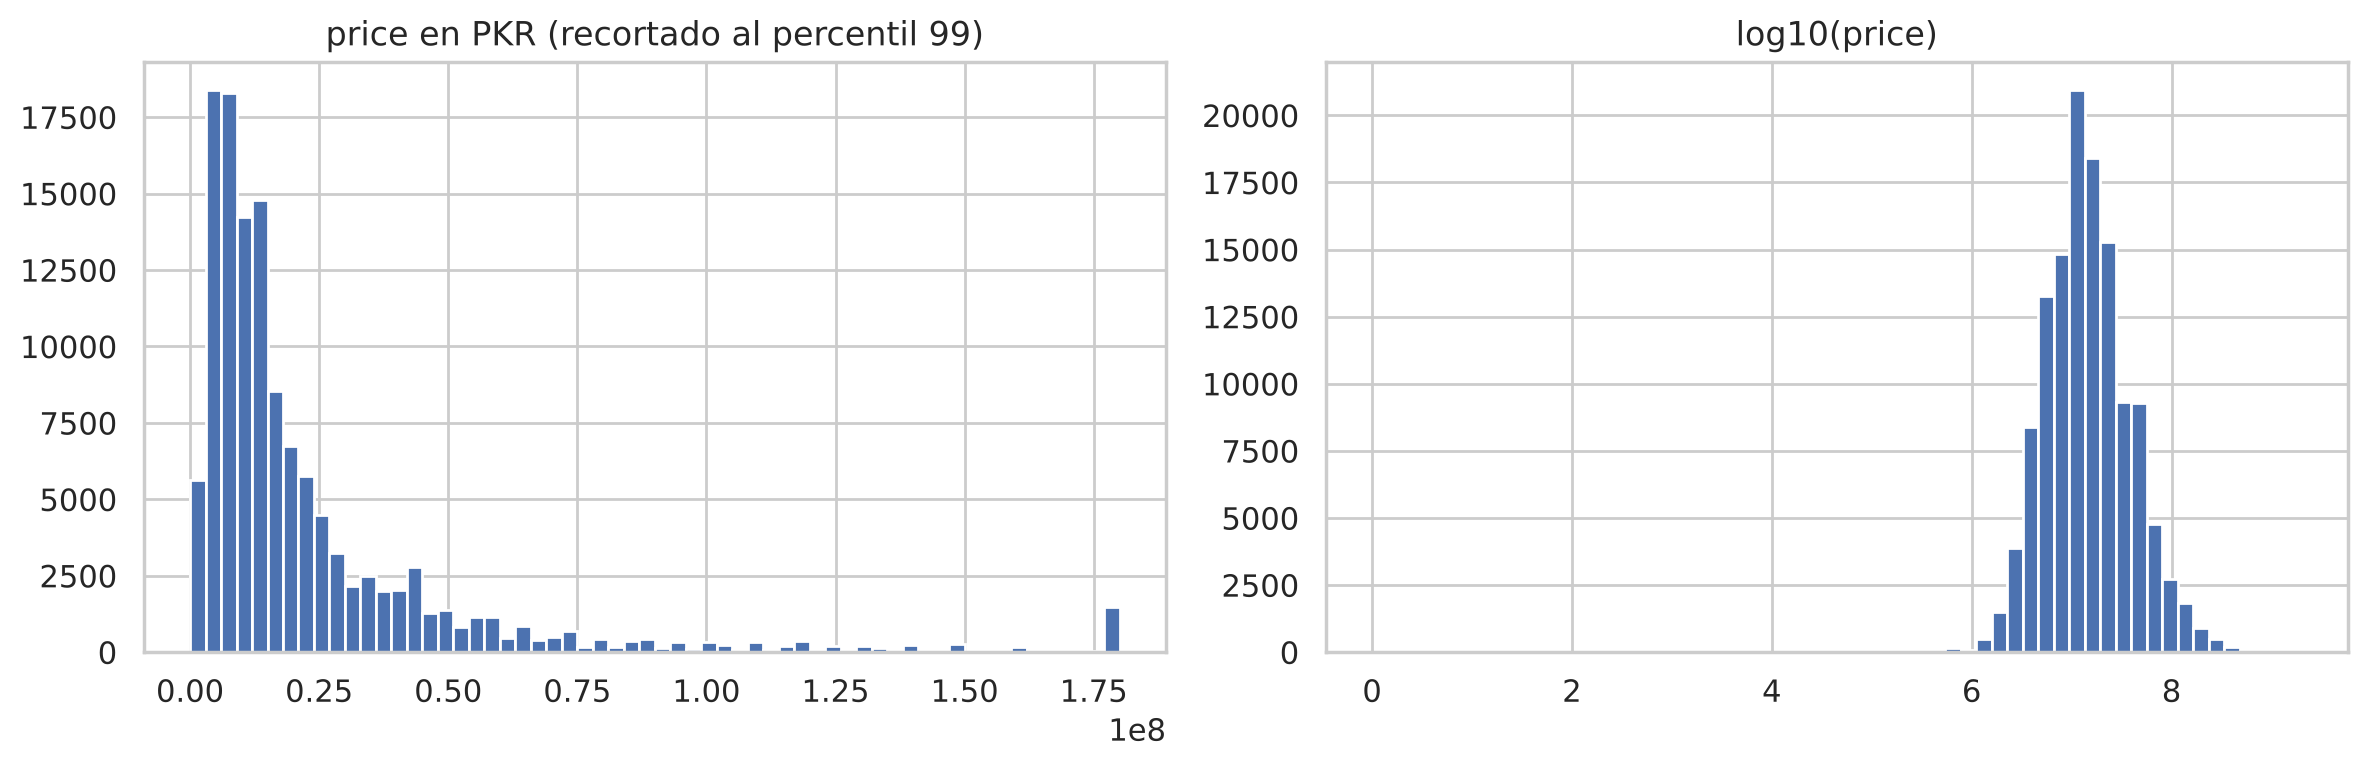

Asimetría de price:      8.72
Asimetría de log(price): -0.32
Ventas con precio < 1.000 € (179,61 PKR/€): 93


In [14]:
precio = df.loc[venta & (df["price"] > 0), "price"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(precio.clip(upper=precio.quantile(0.99)), bins=60)
axes[0].set_title("price en PKR (recortado al percentil 99)")
axes[1].hist(np.log10(precio), bins=60)
axes[1].set_title("log10(price)")
plt.tight_layout()
plt.show()

print(f"Asimetría de price:      {precio.skew():.2f}")
print(f"Asimetría de log(price): {np.log(precio).skew():.2f}")
print("Ventas con precio < 1.000 € (179,61 PKR/€):", (precio / 179.61 < 1000).sum())

`price` tiene una cola muy larga a la derecha (asimetría 8,7) que desaparece en escala logarítmica (asimetría −0,3). Además hay 93 ventas con un precio inferior a 1.000 €, que no corresponden a una venta real.

**Acción:** modelar `log(price)` como target y filtrar los precios por debajo de 1.000 €. Los precios altos se conservan: son propiedades caras reales.

## 7. Conclusiones y acciones

| Hallazgo | Acción | Dónde |
|---|---|---|
| Un tercio de los anuncios (32,5 %) repite a otro salvo en la fecha | Quitar repeticiones al final de la limpieza y agrupar en la partición train/test | Limpieza previa y partición |
| `agency` y `agent` con 25 % de nulos y sin valor predictivo; `property_id` y `page_url` son identificadores | Descartar | Limpieza previa |
| `area` es texto en Marla y Kanal, con decimales y comas de miles | Convertir a m² | Limpieza previa |
| Superficies de 0 m² y de hasta 3,1 millones de m² | Límites por tipo de propiedad | Limpieza previa |
| 23,6 % de ventas con 0 baños y 11,2 % con 0 habitaciones, desigual por ciudad | Tratarlos como ausentes e imputar después del split, solo con train | Limpieza posterior (decisión pendiente del grupo) |
| 7.563 casas con 7 a 12 baños son reales; los valores imposibles empiezan por encima de 12 | Descartar solo más de 12 baños o habitaciones | Limpieza previa (decisión pendiente del grupo) |
| Coordenadas fuera de rango y solo a nivel de subzona | Calcular `dist_centro_km` y quitar lo que esté a más de 100 km | Limpieza previa |
| Mezcla de ventas (66 %) y alquileres (34 %) | Quedarnos con `For Sale`, lo primero | Limpieza previa |
| `price` en PKR, con 3 ceros y 93 ventas por debajo de 1.000 € | Pasar a euros y filtrar el precio mínimo | Limpieza previa |
| `location` (1.536) y `location_id` (4.321) con cardinalidad muy alta; 66 nombres repetidos entre ciudades | Conservar ambas y codificarlas con el precio medio por (`city`, `location`), solo con train | Limpieza posterior |
| `date_added` es la fecha de la última actualización (72 % en junio y julio de 2019) | No usarla para tendencias; decidir si se descarta | Por decidir |
| `price` muy asimétrica (8,7) | Modelar `log(price)` | EDA y modelado |
